In [4]:
from ultralytics import YOLO
from pathlib import Path
import numpy as np
import pandas as pd

In [5]:
# ============================================================
# CONFIGURATION
# ============================================================

MODEL_PATH = Path(
    r"D:\sih-rdd2022\datasets\processed\rdd4\runs\yolov8s_rdd4\weights\best.pt"
)

CONF_THRESHOLD = 0.20
IMAGE_SIZE = 640

# Test image directory
VAL_IMAGES = Path(
    r"D:\sih-rdd2022\datasets\processed\rdd4\images\val"
)

# Output directory
OUTPUT_DIR = Path(
    r"D:\sih-rdd2022\inference_outputs"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Model path :", MODEL_PATH)
print("Model exists:", MODEL_PATH.exists())
print("Validation images:", VAL_IMAGES)
print("Output directory:", OUTPUT_DIR)

Model path : D:\sih-rdd2022\datasets\processed\rdd4\runs\yolov8s_rdd4\weights\best.pt
Model exists: True
Validation images: D:\sih-rdd2022\datasets\processed\rdd4\images\val
Output directory: D:\sih-rdd2022\inference_outputs


In [6]:
# ============================================================
# LOAD TRAINED MODEL
# ============================================================

model = YOLO(str(MODEL_PATH))

print("Model loaded successfully!")
print("Model:", MODEL_PATH)
print("Classes:", model.names)

Model loaded successfully!
Model: D:\sih-rdd2022\datasets\processed\rdd4\runs\yolov8s_rdd4\weights\best.pt
Classes: {0: 'D00', 1: 'D10', 2: 'D20', 3: 'D40'}


In [7]:
# ============================================================
# DAMAGE DETECTION FUNCTION
# ============================================================

def detect_damage(image):
    """
    Detect road damage in an image.

    Parameters
    ----------
    image : str, Path, or numpy array
        Input image.

    Returns
    -------
    dict
        Structured detection result.
    """

    results = model.predict(
        source=image,
        conf=CONF_THRESHOLD,
        imgsz=IMAGE_SIZE,
        device=0,
        verbose=False
    )

    result = results[0]

    detections = []

    if result.boxes is not None:

        for box in result.boxes:

            class_id = int(box.cls[0])
            confidence = float(box.conf[0])

            x1, y1, x2, y2 = box.xyxy[0].cpu().numpy()

            detections.append({
                "class_id": class_id,
                "class": model.names[class_id],
                "confidence": round(confidence, 4),
                "bbox": [
                    round(float(x1), 2),
                    round(float(y1), 2),
                    round(float(x2), 2),
                    round(float(y2), 2)
                ]
            })

    return {
        "detections": detections,
        "count": len(detections)
    }

In [8]:
# ============================================================
# SINGLE IMAGE TEST
# ============================================================

test_images = list(VAL_IMAGES.glob("*.jpg"))

print("Images available:", len(test_images))

if not test_images:
    print("No JPG images found.")
else:

    test_image = test_images[0]

    print("Testing image:")
    print(test_image)

    output = detect_damage(test_image)

    print("\nDetection result:")
    print(output)

Images available: 3408
Testing image:
D:\sih-rdd2022\datasets\processed\rdd4\images\val\India_India_000003.jpg

Detection result:
{'detections': [], 'count': 0}


In [9]:
# ============================================================
# MULTI-IMAGE TEST
# ============================================================

sample_images = test_images[:20]

results_summary = []

for image_path in sample_images:

    result = detect_damage(image_path)

    results_summary.append({
        "image": image_path.name,
        "detections": result["count"]
    })

df = pd.DataFrame(results_summary)

print(df.to_string(index=False))

                 image  detections
India_India_000003.jpg           0
India_India_000011.jpg           0
India_India_000043.jpg           6
India_India_000086.jpg           4
India_India_000099.jpg           1
India_India_000101.jpg           0
India_India_000104.jpg           1
India_India_000108.jpg           0
India_India_000109.jpg           2
India_India_000116.jpg           0
India_India_000121.jpg           0
India_India_000124.jpg           0
India_India_000131.jpg           2
India_India_000136.jpg           1
India_India_000142.jpg           2
India_India_000191.jpg           1
India_India_000194.jpg           0
India_India_000198.jpg           0
India_India_000200.jpg           1
India_India_000205.jpg           1


In [10]:
# ============================================================
# GENERATE STRUCTURED PREDICTIONS
# ============================================================

prediction_rows = []

for image_path in test_images:

    result = detect_damage(image_path)

    for detection in result["detections"]:

        x1, y1, x2, y2 = detection["bbox"]

        prediction_rows.append({
            "image": image_path.name,
            "class_id": detection["class_id"],
            "class": detection["class"],
            "confidence": detection["confidence"],
            "x1": x1,
            "y1": y1,
            "x2": x2,
            "y2": y2
        })

predictions_df = pd.DataFrame(prediction_rows)

csv_path = OUTPUT_DIR / "predictions.csv"

predictions_df.to_csv(csv_path, index=False)

print("Inference completed.")
print("Total detections:", len(predictions_df))
print("CSV saved to:")
print(csv_path)

Inference completed.
Total detections: 6443
CSV saved to:
D:\sih-rdd2022\inference_outputs\predictions.csv


In [11]:
# ============================================================
# CLASS-WISE PREDICTION SUMMARY
# ============================================================

if not predictions_df.empty:

    class_counts = (
        predictions_df["class"]
        .value_counts()
        .reindex(["D00", "D10", "D20", "D40"], fill_value=0)
    )

    print("\nClass-wise detections:")
    
    for class_name, count in class_counts.items():
        print(f"{class_name}: {count}")

else:

    print("No detections found.")


Class-wise detections:
D00: 2440
D10: 1003
D20: 1854
D40: 1146


In [12]:
# ============================================================
# GENERATE ANNOTATED INFERENCE IMAGES
# ============================================================

ANNOTATED_DIR = OUTPUT_DIR / "annotated"
ANNOTATED_DIR.mkdir(parents=True, exist_ok=True)

print("Generating annotated images...")

results = model.predict(
    source=str(VAL_IMAGES),
    conf=CONF_THRESHOLD,
    imgsz=IMAGE_SIZE,
    device=0,
    save=True,
    project=str(OUTPUT_DIR),
    name="annotated",
    exist_ok=True,
    stream=True,
    verbose=False
)

count = 0

for result in results:
    count += 1

    if count % 100 == 0:
        print(f"Processed {count} images...")

print("\nAnnotated inference complete!")
print("Images saved to:")
print(ANNOTATED_DIR)

Generating annotated images...
Processed 100 images...
Processed 200 images...
Processed 300 images...
Processed 400 images...
Processed 500 images...
Processed 600 images...
Processed 700 images...
Processed 800 images...
Processed 900 images...
Processed 1000 images...
Processed 1100 images...
Processed 1200 images...
Processed 1300 images...
Processed 1400 images...
Processed 1500 images...
Processed 1600 images...
Processed 1700 images...
Processed 1800 images...
Processed 1900 images...
Processed 2000 images...
Processed 2100 images...
Processed 2200 images...
Processed 2300 images...
Processed 2400 images...
Processed 2500 images...
Processed 2600 images...
Processed 2700 images...
Processed 2800 images...
Processed 2900 images...
Processed 3000 images...
Processed 3100 images...
Processed 3200 images...
Processed 3300 images...
Processed 3400 images...
Results saved to D:\sih-rdd2022\inference_outputs\annotated

Annotated inference complete!
Images saved to:
D:\sih-rdd2022\infer

In [13]:
# ============================================================
# CHECK ANNOTATED OUTPUT
# ============================================================

annotated_images = list(ANNOTATED_DIR.glob("*.jpg"))

print("Annotated images generated:", len(annotated_images))

if annotated_images:
    print("\nExample files:")
    for image in annotated_images[:10]:
        print(image.name)

Annotated images generated: 3408

Example files:
India_India_000003.jpg
India_India_000011.jpg
India_India_000043.jpg
India_India_000086.jpg
India_India_000099.jpg
India_India_000101.jpg
India_India_000104.jpg
India_India_000108.jpg
India_India_000109.jpg
India_India_000116.jpg


India_India_000003.jpg


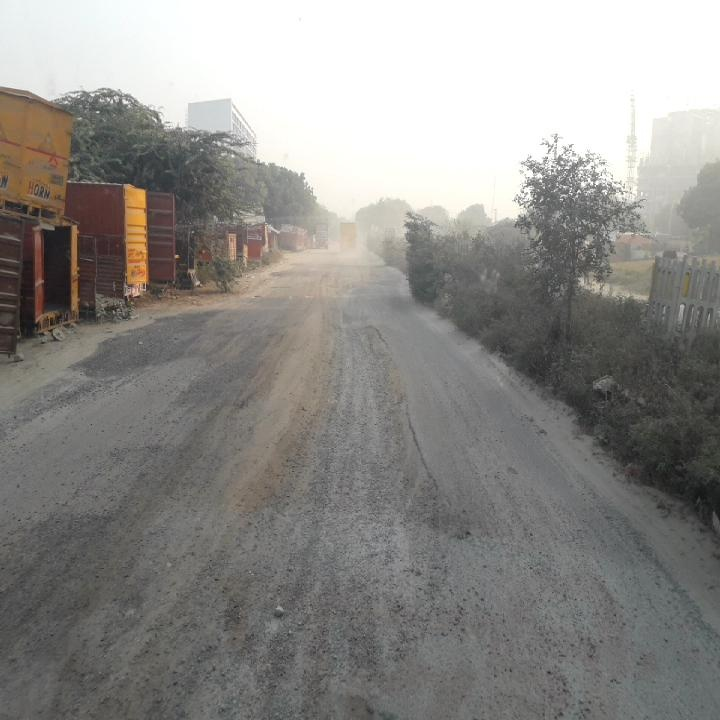

India_India_000011.jpg


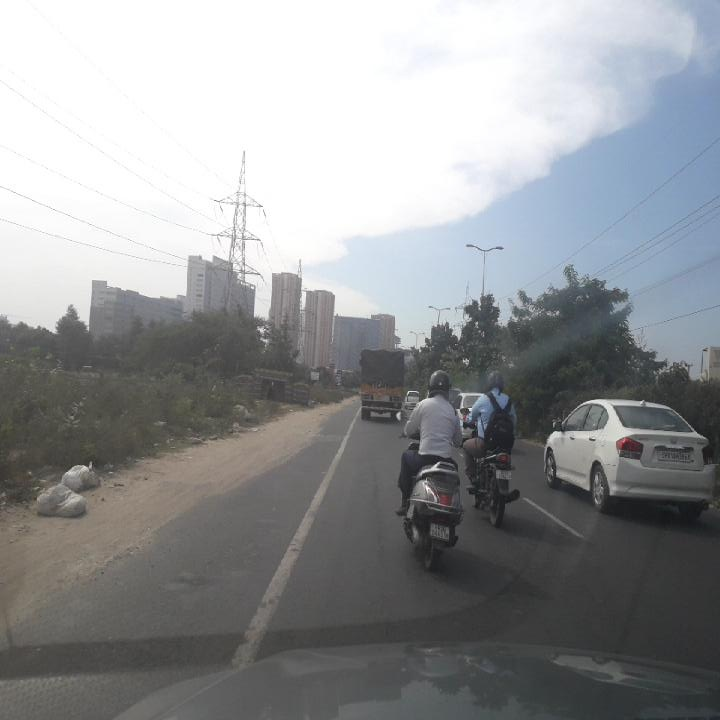

India_India_000043.jpg


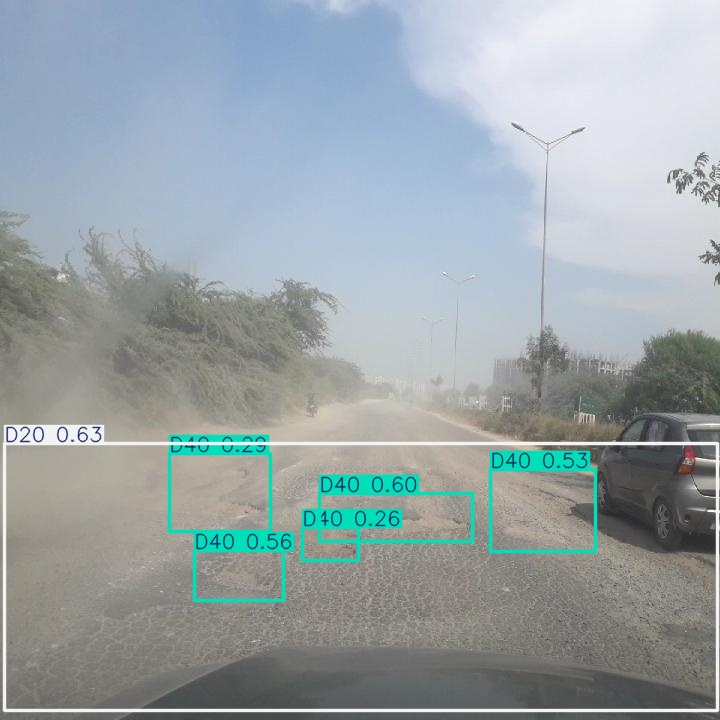

India_India_000086.jpg


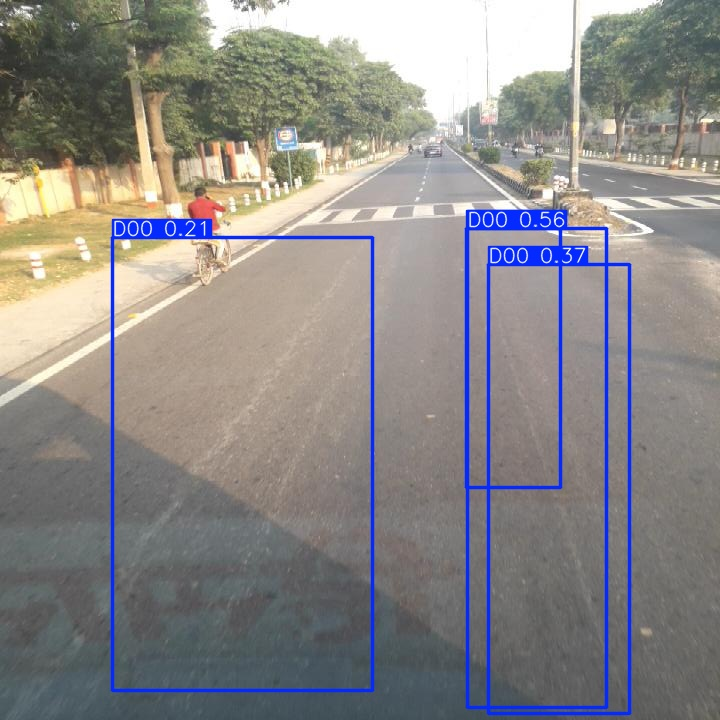

India_India_000099.jpg


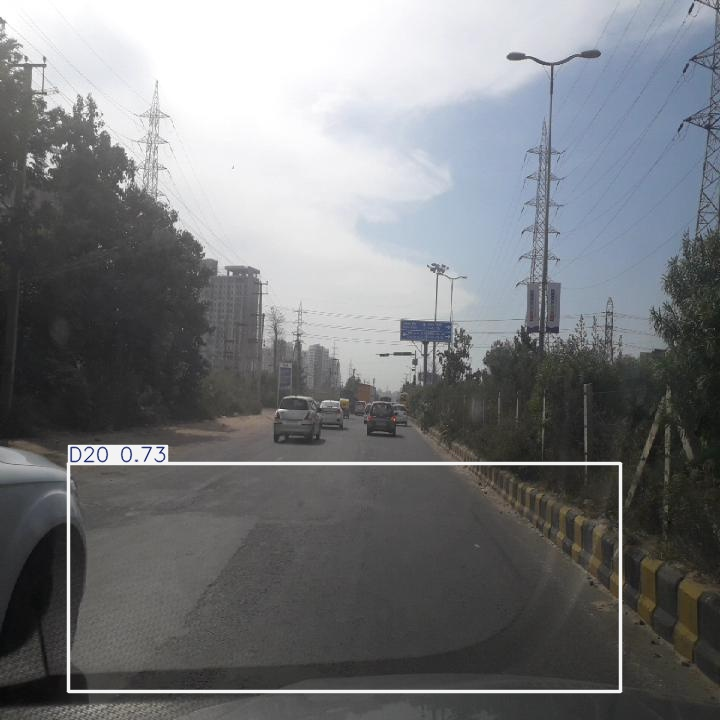

In [14]:
# ============================================================
# DISPLAY SAMPLE ANNOTATED RESULTS
# ============================================================

from IPython.display import display
from PIL import Image

sample_images = annotated_images[:5]

for image_path in sample_images:
    print(image_path.name)
    display(Image.open(image_path))

In [15]:
# ============================================================
# CREATE API-READY JSON OUTPUT
# ============================================================

import json

API_OUTPUT_DIR = OUTPUT_DIR / "api_samples"
API_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Use one image automatically
api_test_image = test_images[0]

api_result = detect_damage(api_test_image)

api_output = {
    "image": api_test_image.name,
    "damage_detected": api_result["count"] > 0,
    "damage_count": api_result["count"],
    "detections": api_result["detections"]
}

json_path = API_OUTPUT_DIR / "sample_response.json"

with open(json_path, "w", encoding="utf-8") as f:
    json.dump(api_output, f, indent=4)

print("API-ready response:")
print(json.dumps(api_output, indent=4))

print("\nJSON saved to:")
print(json_path)

API-ready response:
{
    "image": "India_India_000003.jpg",
    "damage_detected": false,
    "damage_count": 0,
    "detections": []
}

JSON saved to:
D:\sih-rdd2022\inference_outputs\api_samples\sample_response.json


In [16]:
# ============================================================
# FIND AN IMAGE WITH DETECTIONS AUTOMATICALLY
# ============================================================

demo_image = None
demo_result = None

for image_path in test_images:
    result = detect_damage(image_path)

    if result["count"] > 0:
        demo_image = image_path
        demo_result = result
        break

if demo_image is None:
    print("No image with detections found.")
else:
    print("Demo image:")
    print(demo_image)

    print("\nAPI-ready response:")
    print(json.dumps({
        "image": demo_image.name,
        "damage_detected": True,
        "damage_count": demo_result["count"],
        "detections": demo_result["detections"]
    }, indent=4))

Demo image:
D:\sih-rdd2022\datasets\processed\rdd4\images\val\India_India_000043.jpg

API-ready response:
{
    "image": "India_India_000043.jpg",
    "damage_detected": true,
    "damage_count": 6,
    "detections": [
        {
            "class_id": 2,
            "class": "D20",
            "confidence": 0.6327,
            "bbox": [
                4.16,
                443.84,
                717.79,
                710.8
            ]
        },
        {
            "class_id": 3,
            "class": "D40",
            "confidence": 0.5989,
            "bbox": [
                319.24,
                493.8,
                472.26,
                541.92
            ]
        },
        {
            "class_id": 3,
            "class": "D40",
            "confidence": 0.5566,
            "bbox": [
                194.14,
                550.52,
                283.49,
                600.59
            ]
        },
        {
            "class_id": 3,
            "class": "D40

In [17]:
# ============================================================
# INFERENCE SUMMARY
# ============================================================

print("=" * 55)
print("INFERENCE SUMMARY")
print("=" * 55)

print(f"Model          : {MODEL_PATH.name}")
print(f"Confidence     : {CONF_THRESHOLD}")
print(f"Image size     : {IMAGE_SIZE}")
print(f"Images tested  : {len(test_images)}")
print(f"Total detections: {len(predictions_df)}")

print("\nClass-wise detections:")

if not predictions_df.empty:

    class_counts = (
        predictions_df["class"]
        .value_counts()
        .reindex(["D00", "D10", "D20", "D40"], fill_value=0)
    )

    for class_name, count in class_counts.items():
        print(f"  {class_name}: {count}")

print("\nOutput files:")
print(f"  Predictions : {OUTPUT_DIR / 'predictions.csv'}")
print(f"  Annotated   : {ANNOTATED_DIR}")
print(f"  API samples : {API_OUTPUT_DIR}")

print("=" * 55)

INFERENCE SUMMARY
Model          : best.pt
Confidence     : 0.2
Image size     : 640
Images tested  : 3408
Total detections: 6443

Class-wise detections:
  D00: 2440
  D10: 1003
  D20: 1854
  D40: 1146

Output files:
  Predictions : D:\sih-rdd2022\inference_outputs\predictions.csv
  Annotated   : D:\sih-rdd2022\inference_outputs\annotated
  API samples : D:\sih-rdd2022\inference_outputs\api_samples
